In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import (
    MinMaxScaler, StandardScaler, RobustScaler,
    LabelEncoder, OrdinalEncoder, OneHotEncoder
)
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True

np.random.seed(42)
n = 800

df = pd.DataFrame({
    'Age':         np.random.randint(18, 76, n),
    'Income':      np.random.lognormal(mean=10.5, sigma=0.9, size=n).round(0),
    'Tenure':      np.random.randint(1, 61, n),
    'CreditScore': np.random.randint(300, 851, n),
    'Gender':      np.random.choice(['M', 'F'], n, p=[0.55, 0.45]),
    'Education':   np.random.choice(
                       ['High School', 'Bachelor', 'Master', 'PhD'],
                       n, p=[0.30, 0.45, 0.20, 0.05]),
    'City':        np.random.choice(
                       ['Moscow', 'SPb', 'Kazan', 'Ufa',
                        'Novosibirsk', 'Ekaterinburg'], n),
})

# Один выброс в доходе для демонстрации
df.loc[0, 'Income'] = 5_000_000

# Целевая переменная зависит от признаков
churn_logit = (
    -0.8
    + 0.04 * (df['Age'] - 45)
    + 1.2 * (df['Tenure'] < 12).astype(int)
)
p_churn = 1 / (1 + np.exp(-churn_logit))
df['Churn'] = np.random.binomial(1, p_churn)

df.to_csv('bank_customers.csv', index=False)

print(df.head())
print(f"Размер: {df.shape}")
print(f"Средний Churn: {df['Churn'].mean():.3f}")
print(df.dtypes)

   Age     Income  Tenure  CreditScore Gender    Education          City  \
0   56  5000000.0      15          369      M       Master           Ufa   
1   69    24836.0      21          510      M       Master  Ekaterinburg   
2   46   133169.0      19          400      M  High School           Ufa   
3   32     6481.0      60          431      F     Bachelor           SPb   
4   60    78179.0      29          680      M     Bachelor           SPb   

   Churn  
0      0  
1      0  
2      0  
3      0  
4      0  
Размер: (800, 8)
Средний Churn: 0.371
Age              int64
Income         float64
Tenure           int64
CreditScore      int64
Gender          object
Education       object
City            object
Churn            int64
dtype: object


### 1.1 SMART-цель
Снизить долю оттока клиентов (Churn) на 15% в сегменте новых клиентов (Tenure < 12 месяцев) за 6 месяцев за счёт внедрения программы лояльности и персональных скидок.

- **S (Конкретность):** Снизить отток именно в сегменте новых клиентов.
- **M (Измеримость):** Метрика — доля оттока (Churn rate), цель — минус 15%.
- **A (Достижимость):** Внедрение программы лояльности — реалистичный шаг для банка.
- **R (Значимость):** Удержание новых клиентов напрямую увеличивает прибыль.
- **T (Ограничение по времени):** За 6 месяцев.

In [2]:
# Создаем дерево в виде словаря
decomposition_tree = {
    "Отток клиентов": {
        "Число активных клиентов": ["Новые клиенты", "Уходящие клиенты (churn_rate)", "Потерянные из-за неактивности"],
        "Доход с клиента": ["Средний доход на клиента", "Частота транзакций", "Средний чек"],
        "Качество обслуживания": ["Кол-во обращений в поддержку", "Скорость ответа (часы)", "Оценка NPS (CSI)"]
    }
}

# Функция для красивого вывода дерева
def print_tree(tree, level=0):
    for key, value in tree.items():
        print("  " * level + "- " + key)
        if isinstance(value, dict):
            print_tree(value, level + 1)
        elif isinstance(value, list):
            for item in value:
                print("  " * (level + 1) + "- " + item)

print_tree(decomposition_tree)

- Отток клиентов
  - Число активных клиентов
    - Новые клиенты
    - Уходящие клиенты (churn_rate)
    - Потерянные из-за неактивности
  - Доход с клиента
    - Средний доход на клиента
    - Частота транзакций
    - Средний чек
  - Качество обслуживания
    - Кол-во обращений в поддержку
    - Скорость ответа (часы)
    - Оценка NPS (CSI)


**Ответы:**
1. **Дерево взаимоисключающее?** Да. Ветка "Доход" и "Число клиентов" пересекаются в понятии "LTV" (пожизненная ценность), но мы разбили их по разным аспектам: количество и деньги.
2. **Дерево полное?** Для текущего датасета — да. Но в реальности упущена ветка "Действия конкурентов" (например, конкуренты предложили ставку ниже).
3. **Все листья измеримы?** На текущем датасете мы можем посчитать `churn_rate` (доля Churn=1), `avg_income` (медиана/среднее Income) и `avg_tenure`. А вот "Скорость ответа поддержки" нам не измерить — этих данных нет в таблице, их нужно запросить.

In [3]:
biases = {
    "1. Изучение успешных стартапов": ("survivorship", "Мы видим только выживших. Те, кто обанкротился, не попали в статистику, поэтому мы не знаем их ошибок."),
    "2. Опрос на сайте банка": ("selection", "Опрашиваются только те, кто заходит на сайт. Пенсионеры, которые ходят в отделения, не попадут в выборку."),
    "3. Обучение на клиентах из Google": ("selection", "Модель не увидит клиентов из других источников (VK, рефералы) и будет предвзята к аудитории Google."),
    "4. Вопрос 'сколько раз были в банке'": ("recall", "Люди не помнят точных цифр за год, они будут угадывать (ошибка памяти/воспоминания).")
}

for q, (b_type, explanation) in biases.items():
    print(f"{q}\n-> Тип: {b_type}\n-> Обоснование: {explanation}\n")

1. Изучение успешных стартапов
-> Тип: survivorship
-> Обоснование: Мы видим только выживших. Те, кто обанкротился, не попали в статистику, поэтому мы не знаем их ошибок.

2. Опрос на сайте банка
-> Тип: selection
-> Обоснование: Опрашиваются только те, кто заходит на сайт. Пенсионеры, которые ходят в отделения, не попадут в выборку.

3. Обучение на клиентах из Google
-> Тип: selection
-> Обоснование: Модель не увидит клиентов из других источников (VK, рефералы) и будет предвзята к аудитории Google.

4. Вопрос 'сколько раз были в банке'
-> Тип: recall
-> Обоснование: Люди не помнят точных цифр за год, они будут угадывать (ошибка памяти/воспоминания).



In [4]:
numeric_cols = ['Age', 'Income', 'Tenure', 'CreditScore']
nominal_cols = ['Gender', 'City']
ordinal_cols = ['Education']

print(f"Числовые: {numeric_cols}")
print(f"Номинальные: {nominal_cols}")
print(f"Порядковые: {ordinal_cols}")

# Анализ выбросов
print("\nОписательные статистики:")
print(df[numeric_cols].describe().round(1))

# Правило 3-х сигм
z_scores = (df[numeric_cols] - df[numeric_cols].mean()) / df[numeric_cols].std()
print("\nКоличество выбросов (Z > 3):")
print((z_scores.abs() > 3).sum())

Числовые: ['Age', 'Income', 'Tenure', 'CreditScore']
Номинальные: ['Gender', 'City']
Порядковые: ['Education']

Описательные статистики:
         Age     Income  Tenure  CreditScore
count  800.0      800.0   800.0        800.0
mean    47.1    67728.3    29.5        578.8
std     16.6   188315.9    17.0        159.4
min     18.0     2963.0     1.0        300.0
25%     33.0    20203.5    15.0        440.0
50%     47.5    38086.0    29.0        576.0
75%     61.0    75490.2    44.0        720.0
max     75.0  5000000.0    60.0        850.0

Количество выбросов (Z > 3):
Age            0
Income         1
Tenure         0
CreditScore    0
dtype: int64


**Обоснование типов признаков:**
- `Education` — порядковый, так как уровни образования имеют четкую иерархию (High School < Bachelor < Master < PhD).
- `City` — номинальный, так как города не имеют ранжирования (Москва не "больше" или "лучше" Казани, это просто разные категории).

**Анализ выбросов:**
По правилу Z-оценки (отклонение больше 3 сигм), выброс найден в столбце `Income` (это тот самый клиент с 5 000 000).
Для этого столбца я выберу `RobustScaler`, потому что он использует медиану и межквартильный размах (IQR), которые не чувствительны к таким экстремальным значениям.

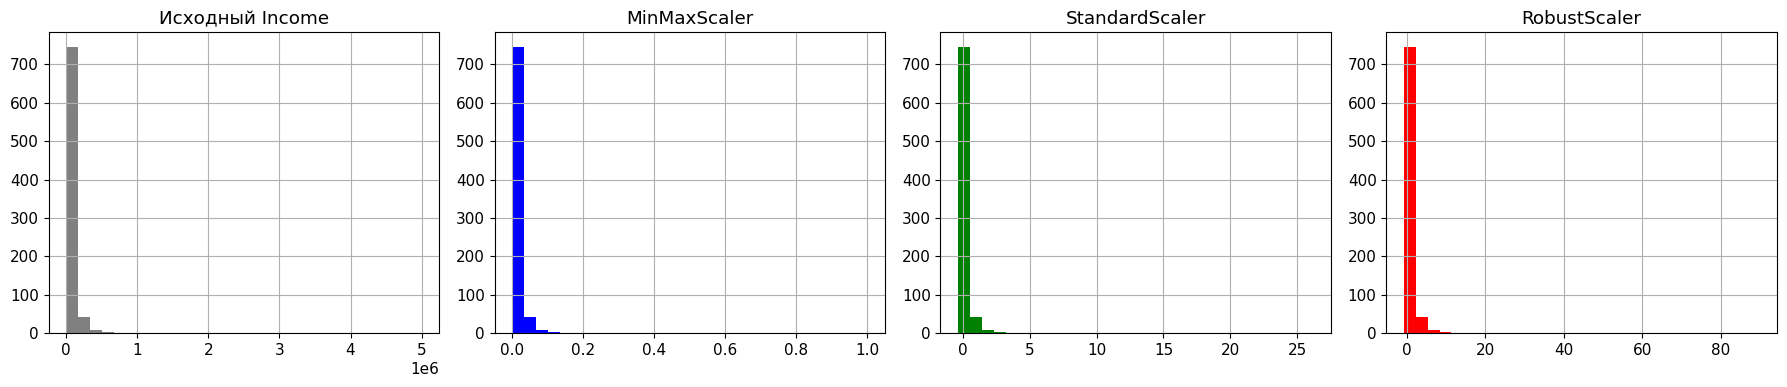

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

# Исходный
axes[0].hist(df['Income'], bins=30, color='gray')
axes[0].set_title('Исходный Income')

# MinMax
mm = MinMaxScaler()
income_mm = mm.fit_transform(df[['Income']])
axes[1].hist(income_mm, bins=30, color='blue')
axes[1].set_title('MinMaxScaler')

# Standard
ss = StandardScaler()
income_ss = ss.fit_transform(df[['Income']])
axes[2].hist(income_ss, bins=30, color='green')
axes[2].set_title('StandardScaler')

# Robust
rs = RobustScaler()
income_rs = rs.fit_transform(df[['Income']])
axes[3].hist(income_rs, bins=30, color='red')
axes[3].set_title('RobustScaler')

plt.tight_layout()
plt.show()

1. **Форма лучше всего сохранилась** после `RobustScaler`. Он вычитает медиану и делит на IQR, поэтому выброс в 5 млн просто остается "далеко справа", не сжимая остальные данные.
2. **Сильнее всего пострадал MinMaxScaler.** Он берет минимум и максимум. Из-за выброса в 5 000 000, все остальные доходы (от 10 000 до 200 000) сжались в крошечную точку у нуля.
3. Для `Income` в продакшене я выберу **RobustScaler**, так как доходы людей часто имеют "тяжелые хвосты" (олигархи, крупные бизнесмены), и мы не хотим, чтобы один богач ломал нам всю шкалу.

In [6]:
scaler_choice = {
    'Age': 'MinMaxScaler',
    'Income': 'RobustScaler',
    'Tenure': 'MinMaxScaler',
    'CreditScore': 'StandardScaler'
}

justification = {
    'Age': 'Возраст имеет четкие границы (18-75), выбросов нет.',
    'Income': 'Есть сильный выброс (5 млн), нужен устойчивый скейлер.',
    'Tenure': 'Стаж измеряется в месяцах (1-60), границы известны.',
    'CreditScore': 'Скор имеет фиксированный диапазон (300-850), нормальное распределение.'
}

for col, scaler in scaler_choice.items():
    print(f"{col}: {scaler} — {justification[col]}")

Age: MinMaxScaler — Возраст имеет четкие границы (18-75), выбросов нет.
Income: RobustScaler — Есть сильный выброс (5 млн), нужен устойчивый скейлер.
Tenure: MinMaxScaler — Стаж измеряется в месяцах (1-60), границы известны.
CreditScore: StandardScaler — Скор имеет фиксированный диапазон (300-850), нормальное распределение.


In [7]:
# 4.1 Label Encoding для Gender
df['Gender_Label'] = LabelEncoder().fit_transform(df['Gender'])
print("Label Encoding для Gender:")
print(df[['Gender', 'Gender_Label']].drop_duplicates())

# One-Hot Encoding для Gender
df_ohe = pd.get_dummies(df['Gender'], prefix='Gender', dtype=int)
print("\nOne-Hot Encoding для Gender:")
print(df_ohe.head())

# 4.2 Ordinal Encoding для Education
edu_order = ['High School', 'Bachelor', 'Master', 'PhD']
oe = OrdinalEncoder(categories=[edu_order])
df['Education_Ord'] = oe.fit_transform(df[['Education']])
print("\nOrdinal Encoding для Education:")
print(df[['Education', 'Education_Ord']].drop_duplicates().sort_values('Education_Ord'))

Label Encoding для Gender:
  Gender  Gender_Label
0      M             1
3      F             0

One-Hot Encoding для Gender:
   Gender_F  Gender_M
0         0         1
1         0         1
2         0         1
3         1         0
4         0         1

Ordinal Encoding для Education:
      Education  Education_Ord
2   High School            0.0
3      Bachelor            1.0
0        Master            2.0
19          PhD            3.0


**4.1 Label vs One-Hot:**
Label-кодирование (замена на 0 и 1) допустимо для **деревьев решений** (Random Forest, XGBoost), так как они могут разбивать условием `> 0.5`. Но для **линейных моделей** (Логистическая регрессия, SVM) это **недопустимо**, потому что модель решит, что "М" (1) в два раза больше "Ж" (0), что не имеет физического смысла. Для линейных моделей нужен One-Hot.

**4.2 Ordinal для Education:**
Если не задать порядок явно, `OrdinalEncoder` отсортирует категории по алфавиту: Bachelor, High School, Master, PhD. То есть "High School" (среднее) получит код 1, а "Bachelor" (высшее) — код 0. Модель подумает, что среднее образование "лучше" высшего. Явное задание порядка `edu_order` это исправляет.

In [8]:
freq_map = df['City'].value_counts()
df['City_Freq'] = df['City'].map(freq_map)
print("Frequency Encoding для City:")
print(df[['City', 'City_Freq']].drop_duplicates())

Frequency Encoding для City:
            City  City_Freq
0            Ufa        115
1   Ekaterinburg        138
3            SPb        140
5    Novosibirsk        139
7         Moscow        135
16         Kazan        133


**Недостаток Frequency Encoding:**
Если два разных города имеют одинаковое количество клиентов, они получат одинаковый код. Модель не сможет их различить, хотя это разные города.
Это критично в тех случаях, когда сама "уникальность" категории важнее её популярности (например, если мы кодируем ID клиентов или конкретные бренды).

In [9]:
# Удаляем лишние столбцы, которые мы создали для тестов
X = df.drop(columns=['Churn', 'Gender_Label', 'Education_Ord', 'City_Freq'])
y = df['Churn']

# Разделяем на Train и Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Создаем пайплайн
preprocessor = ColumnTransformer(
    transformers=[
        ('num_std', StandardScaler(), ['Age', 'CreditScore']),
        ('num_robust', RobustScaler(), ['Income']),
        ('num_minmax', MinMaxScaler(), ['Tenure']),
        ('cat_ohe', OneHotEncoder(drop='first', sparse_output=False), ['Gender', 'City']),
        ('cat_ord', OrdinalEncoder(categories=[edu_order]), ['Education'])
    ]
)

# Обучаем на train, применяем к test
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print(X_train.shape, '->', X_train_prepared.shape)
print(X_test.shape, '->', X_test_prepared.shape)

(600, 7) -> (600, 11)
(200, 7) -> (200, 11)


1. **Почему fit только на train?**
Если сделать `fit` на всей выборке (включая тест), скейлер "подсмотрит" максимальные и минимальные значения из теста. Это называется **утечкой данных**. Когда модель будет проходить тест, она будет знать его границы, что завысит её оценку.
2. **Сколько столбцов даст OHE?**
Для `Gender` (2 уникальных значения, drop='first') — 1 столбец.
Для `City` (6 городов, drop='first') — 5 столбцов.
3. **Если в тесте встретится новый город?**
По умолчанию sklearn проигнорирует его (выдаст ошибку или закодирует нулями, в зависимости от версии). Чтобы это исправить, в `OneHotEncoder` нужно указать параметр `handle_unknown='ignore'`. Тогда он просто создаст вектор из нулей.

In [11]:
def stratified_sample(df, strat_col, n_total, random_state=42):
    # Получаем доли каждого класса (например, 0 - 70%, 1 - 30%)
    fractions = df[strat_col].value_counts(normalize=True)
    samples = []

    # Для каждого класса берем нужное количество строк
    for cls, frac in fractions.items():
        n_cls = int(round(n_total * frac))
        s = df[df[strat_col] == cls].sample(n=n_cls, random_state=random_state)
        samples.append(s)

    return pd.concat(samples)

s_rand = df.sample(n=100, random_state=42)
s_strat = stratified_sample(df, 'Churn', n_total=100)

print(f"Популяция:            {df['Churn'].mean():.3f}")
print(f"Случайная:            {s_rand['Churn'].mean():.3f}")
print(f"Стратифицированная:   {s_strat['Churn'].mean():.3f}")

Популяция:            0.371
Случайная:            0.320
Стратифицированная:   0.370


1. **Какая выборка ближе к популяции?**
Стратифицированная. При простой случайной выборке из 100 человек может случайно оказаться 40% ушедших, а в популяции их 30%. Стратификация жестко сохраняет пропорции (30 на 70). Это критично для несбалансированных классов.
2. **Почему нельзя оставлять Churn в X?**
Если оставить целевую переменную (Churn) среди признаков (X), модель просто выучит правило "Если Churn = 1, значит клиент уйдет". Это и есть утечка целевой переменной. Модель покажет 100% точность на тесте, но в реальности обанкротится.

/tmp/ipykernel_6096/60110256.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([results[n] for n in sizes], labels=[f'n={n}' for n in sizes])


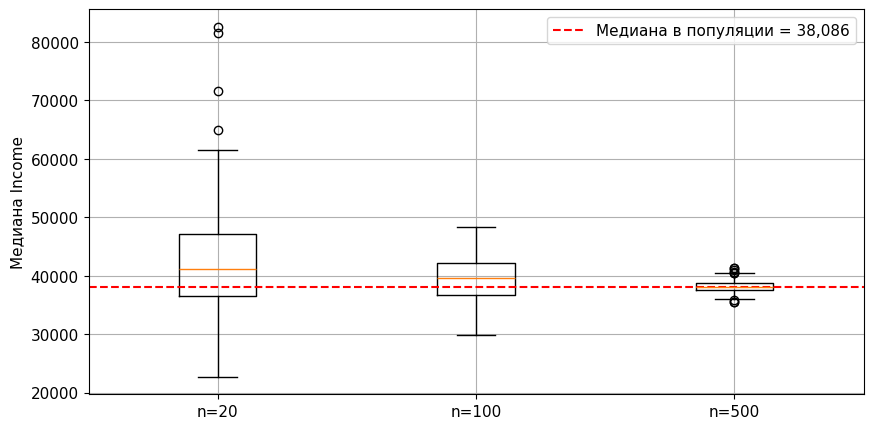

n=20: std = 10,391
n=100: std = 3,887
n=500: std = 1,138


In [12]:
sizes = [20, 100, 500]
results = {n: [] for n in sizes}

for n in sizes:
    for seed in range(100):
        results[n].append(df.sample(n=n, random_state=seed)['Income'].median())

fig, ax = plt.subplots()
ax.boxplot([results[n] for n in sizes], labels=[f'n={n}' for n in sizes])
ax.axhline(df['Income'].median(), color='red', linestyle='--',
           label=f"Медиана в популяции = {df['Income'].median():,.0f}")
ax.set_ylabel('Медиана Income')
ax.legend()
plt.show()

for n in sizes:
    print(f"n={n}: std = {np.std(results[n]):,.0f}")

**Как меняется стандартное отклонение (std)?**
С ростом `n` стандартное отклонение медианы резко падает. Это полностью согласуется с формулой стандартной ошибки `σ / √n`. Чем больше выборка, тем точнее мы оцениваем медиану.
**Что было бы со средним?**
Если бы мы считали среднее, то из-за выброса в 5 миллионов, на маленьких выборках (n=20) среднее скакало бы с невероятной амплитудой. В одной выборке мог бы попасться этот "богач", и среднее стало бы 250 000, а в другой его бы не было, и среднее было бы 50 000. Медиана же устойчива к этому выбросу и показывает стабильный результат.